# Análise de Estabilidade Linear da Convecção Térmica e MRI em Discos de Acreção
- PET - Física
- Petiana: Ylana Karolina Santos Lopes
- Data: 31 de Novembro de 2026

$\quad$ O objetivo deste `Notebook` é fazer uma análise linear da estabilidade seguindo o artigo de Mamatsashvili et al. 2013 [1] em um disco de acreção. Com isso, expandiremos a análise para um cenário com a junção de convecção e instabilidade magnetorotacional atuando nele, analisando o comportamento dos modos de oscilação encontrados. Introduziremos conceitos base de magnetohidrodinâmica para sustentar a explicação da instabilidade e como a convecção entra nesse contexto. Seguiremos a seguinte estrutura:

1. Introdução: O Problema com Transporte de Momento Angular;
2. Aproximação de Caixa de Cisalhamento;
3. Análise de Estabilidade Linear;
4. Classificação dos Modos de Oscilação;
5. Conclusões.


### Nota de Agradecimento

---
O conteúdo deste `Notebook` foi parte do resultado do Programa de Verão no HZDR, sob a supervisão do Dr. Ashish Mishra que idealizou o projeto e o orientou. Deixo aqui meus agradecimentos pela oportunidade.

---

### Importando bibliotecas

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.lines as mlines
from matplotlib.colors import TwoSlopeNorm
import warnings

warnings.filterwarnings('ignore', category=RuntimeWarning)

### Detalhes das bibliotecas


In [2]:
%load_ext version_information
%version_information matplotlib, numpy

Software versions
Python 3.12.3 64bit [GCC 13.3.0]
IPython 9.12.0
OS Linux 7.0.0 38 generic x86_64 with glibc2.39
matplotlib 3.11.2
numpy 1.26.4
Fri Oct 23 14:38:04 2026 -03

## 1. Introdução: O Problema do Transporte Angular

$\quad$ Primeiro, temos que entender qual o sistema que estamos tratando. Discos de acreção são estruturas formadas por matéria que orbita um objeto central devido à sua atração gravitacional. Um exemplo pode ser observado na primeira imagem direta de um buraco negro, na qual vemos o disco de acreção ao seu redor. Como os buracos negros não emitem luz, a imagem mostra principalmente a radiação emitida pela matéria aquecida enquanto orbita o objeto central. Para que essa matéria consiga se deslocar para regiões mais internas do disco, existe um problema fundamental: ela precisa perder momento angular. Caso contrário, continuaria orbitando o objeto central sem conseguir se aproximar significativamente dele. Entretanto, a viscosidade molecular convencional é insuficiente para explicar as taxas de acreção observadas. Por isso, precisamos de um mecanismo mais eficiente capaz de gerar turbulência e transportar momento angular para regiões mais externas do disco.


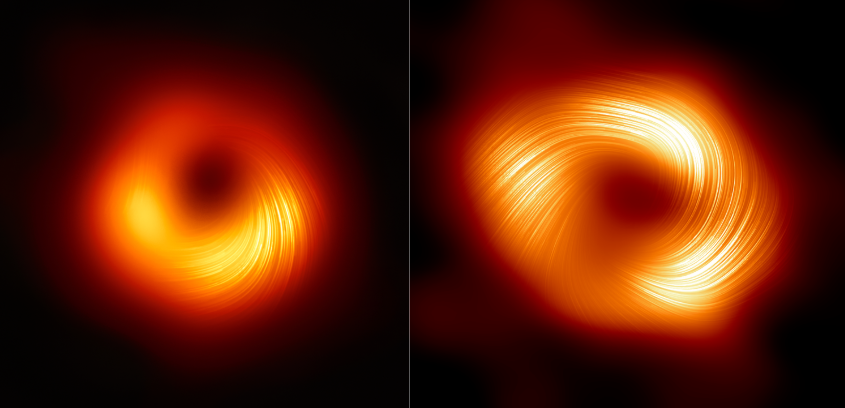

**Figura 1:** Emissão polarizada do buracos negros em M87 e Sgr A*, respectivamente. (ETH Collaboration, 2021,2024)

$\quad$ Um dos principais mecanismos propostos para explicar esse transporte é a instabilidade magnetorrotacional, conhecida como Magnetorotational Instability (MRI).[2] Ela ocorre em fluidos magnetizados com rotação diferencial e mostra que, sob condições apropriadas, mesmo um campo magnético inicialmente fraco pode desestabilizar o escoamento, levando ao desenvolvimento de turbulência magnetohidrodinâmica (MHD). Para compreender melhor esse mecanismo, podemos recorrer a uma analogia com um sistema de duas massas conectadas por uma mola sem massa, que representa a conexão magnética entre diferentes regiões do disco. 


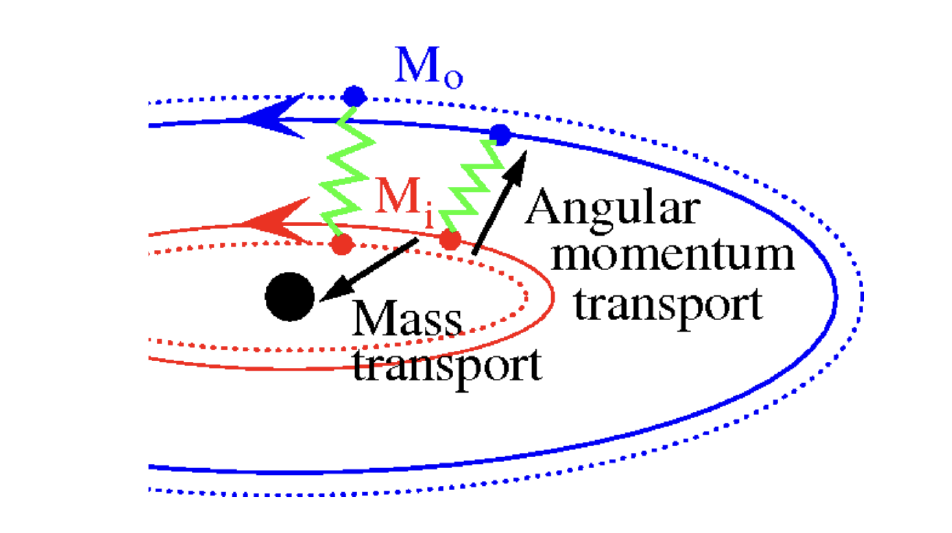

**Figura 2:** Diagrama da analogia da mecânica massa-mola para a instabilidade magnetorotacional. (Mishra,2025)

$\quad$ A mola deve ser entendida como uma conexão relativamente fraca, de modo que pequenas perturbações sejam capazes de deslocar as massas de suas órbitas iniciais. Se a massa vermelha se desloca para uma órbita mais interna, por exemplo, a conexão magnética transmite uma força que transfere momento angular para a massa azul, permitindo que esta se desloque para uma órbita mais externa. Como resultado, ambas se afastam de suas órbitas iniciais, e esse deslocamento pode ser amplificado pela rotação diferencial, fazendo com que as perturbações cresçam progressivamente. Por outro lado, se a conexão magnética fosse excessivamente forte, a tensão magnética tenderia a resistir aos deslocamentos relativos das massas, dificultando o desenvolvimento da instabilidade na escala considerada. Assim, a MRI ilustra como a interação entre um campo magnético fraco e a rotação diferencial pode extrair energia do escoamento e promover o transporte de momento angular necessário à acreção da matéria.[3]

$\quad$ Entretanto, os discos de acreção não são apenas magnetizados: eles também apresentam uma estrutura vertical e uma estratificação térmica que podem favorecer o surgimento de movimentos convectivos. A convecção e a MRI podem, portanto, atuar simultaneamente, influenciando a dinâmica do fluido e o desenvolvimento da turbulência. Nesse contexto, o objetivo do meu projeto é investigar a interação entre esses dois mecanismos, buscando compreender se a convecção térmica pode intensificar ou suprimir a turbulência impulsionada pela MRI. [3,4]

$\quad$ Para entender como as perturbações magnéticas e térmicas iniciais evoluem antes que o sistema alcance um regime plenamente turbulento, começamos com uma análise de estabilidade linear. Essa abordagem permite estudar o comportamento de pequenas perturbações em torno de um estado de equilíbrio e determinar em quais condições elas permanecem estáveis ou crescem ao longo do tempo, fornecendo uma base para investigar como a interação entre convecção e MRI influencia a dinâmica do disco.

## 2. Aproximação Shearing Box

$\quad$ Modelar um disco de acreção inteiro, levando em conta sua geometria curva e sua dinâmica global, pode ser computacionalmente muito custoso. Para simplificar o problema, podemos estudar uma pequena região do disco e assumir que, nessa escala, as propriedades físicas podem ser descritas localmente. Essa abordagem é conhecida como aproximação shearing box. Nela, selecionamos uma pequena região centrada em um raio \(r_0\) e introduzimos um sistema de coordenadas cartesianas local, com os eixos radial, azimutal e vertical representados por \(x\), \(y\) e \(z\), respectivamente. [5]

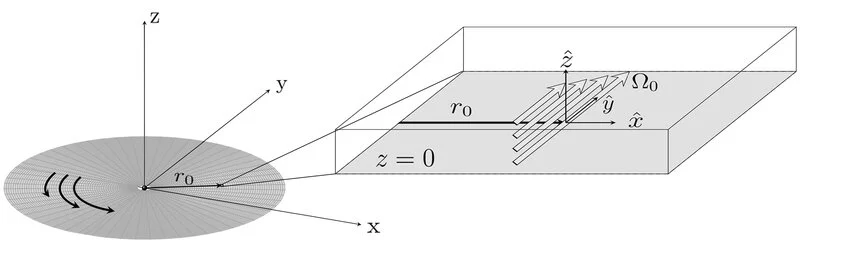

**Figura 3:** Ilustração de uma caixa local para discos de acreção. (Yellin-Bergovoy et al., 2021)

$\quad$ Nesse referencial, a rotação diferencial do disco é descrita localmente por um escoamento de cisalhamento aproximadamente linear, caracterizado pelo parâmetro $q=-d\ln\Omega/d\ln r $, em que $\Omega$ é a velocidade angular do disco. Para um disco Kepleriano, temos $q=3/2$. A condição $q>0$ indica que a velocidade angular diminui com o raio, estabelecendo a rotação diferencial que fornece a energia livre necessária para o desenvolvimento da instabilidade magnetorrotacional (MRI).

$\quad$ Para descrever a dinâmica do fluido e a evolução do campo magnético nessa região, utilizamos as equações da magnetohidrodinâmica (MHD) ideal e incompressível, apresentadas abaixo. Essas equações descrevem a evolução de um fluido condutor, interagindo com um campo magnético no referencial local em rotação, considerando que a viscosidade e a resistividade magnética são desprezíveis. [1,5]

Equação do momento:

$$
\frac{\partial \mathbf{u}}{\partial t}
+ (\mathbf{u}\cdot\nabla)\mathbf{u}
+ 2\boldsymbol{\Omega}\times\mathbf{u}
=
-\frac{1}{\rho}\nabla P
+\frac{(\mathbf{B}\cdot\nabla)\mathbf{B}}{4\pi\rho}
+2q\Omega^2 x\,\hat{\mathbf{x}}
-\Omega^2 z\,\hat{\mathbf{z}}
\tag{1}
$$

Equação de indução magnética:

$$
\frac{\partial \mathbf{B}}{\partial t}
=
\nabla\times(\mathbf{u}\times\mathbf{B})
\tag{2}
$$

Condições de incompressibilidade e ausência de monopolos magnéticos:

$$
\nabla\cdot\mathbf{u}=0
\tag{3}
$$

$$
\nabla\cdot\mathbf{B}=0
\tag{4}
$$

$\quad$ Nessas equações, $\mathbf{u}$ representa o campo de velocidades do fluido, $\mathbf{B}$ é o campo magnético, $\boldsymbol{\Omega}$ é o vetor de velocidade angular do referencial em rotação, $P$ é a pressão do gás, $\rho$ é a densidade de massa e $t$ representa o tempo.

$\quad$ A primeira equação, denominada equação do momento, descreve o movimento do fluido sob a ação de diferentes forças. No lado esquerdo, o primeiro termo representa a variação temporal da velocidade, enquanto o segundo corresponde à aceleração advectiva do fluido. O terceiro termo representa a força de Coriolis, associada ao referencial em rotação. No lado direito, o gradiente de pressão descreve a força exercida pelas diferenças de pressão, enquanto o termo magnético representa a tensão das linhas de campo magnético. Os dois últimos termos correspondem, respectivamente, à contribuição do cisalhamento radial de fundo e à gravidade vertical efetiva. A tensão magnética corresponde à força transmitida pelas linhas de campo e pode ser associada à analogia da mola que conecta duas massas, apresentada anteriormente na explicação da MRI.

$\quad$ A segunda equação, por sua vez, é a equação de indução magnética, que descreve a evolução temporal do campo magnético em função do movimento do fluido. Na aproximação de MHD ideal, as linhas de campo magnético estão congeladas no escoamento, de modo que podem ser esticadas e deformadas pelo movimento do fluido. Por fim, as duas últimas equações representam as condições de incompressibilidade, $\nabla\cdot\mathbf{u}=0$, que impõe divergência nula ao campo de velocidades, e de ausência de monopolos magnéticos, $\nabla\cdot\mathbf{B}=0$, que estabelece que o campo magnético não possui fontes ou sumidouros isolados.

$\quad$ Essas equações constituem o ponto de partida para a análise de estabilidade linear. A partir delas, podemos introduzir pequenas perturbações nas variáveis do sistema e investigar como elas evoluem, identificando as condições em que o acoplamento entre o campo magnético, a rotação diferencial e a estratificação térmica pode levar ao crescimento de instabilidades.

## 3. Análise de Estabilidade Linear

$\quad$ Para transformar as equações de MHD em um problema mais fácil de resolver, aplicamos a teoria de perturbações, introduzindo pequenas variações nas nossas variáveis. Em seguida, assumimos uma solução oscilatória por meio de harmônicos espaciais de Fourier, o que permite eliminar naturalmente os termos não lineares ao longo do desenvolvimento matemático. Também realizamos a adimensionalização, colocando as grandezas em uma escala comum e facilitando a resolução matemática do problema sem a preocupação direta com unidades ou dimensionalidade. [1]

$\quad$ A partir desse processo, dois parâmetros importantes surgem e determinam a física dentro da nossa caixa:

- **Beta do plasma ($\beta$):** É a razão entre a pressão térmica e a pressão magnética. Esse parâmetro indica a intensidade do campo magnético: um valor baixo de $\beta$ corresponde a um campo magnético forte, enquanto um valor alto indica um campo magnético fraco. Ele é definido como:

$$
\beta = \frac{8\pi \rho_0 c_s^2}{B_{0z}^2}.
$$

- **Frequência de Brunt–Väisälä ao quadrado ($N^2$):** Quantifica a estratificação vertical associada à flutuabilidade e à estabilidade térmica. Quando $N^2 > 0$, o disco é convectivamente estável [1]. Por outro lado, quando $N^2 < 0$, o sistema se torna convectivamente instável, permitindo que a flutuabilidade térmica impulsione movimentos convectivos em conjunto com a MRI. No nosso modelo, esse parâmetro é definido como:

$$
N^2 = -\frac{d\ln \rho_0}{d\ln z}.
$$

$\quad$ Para descrever a dependência espacial das perturbações, utilizamos a seguinte ansatz de Fourier espacial:

$$
F(\mathbf{r},t) = \overline{F}(t)e^{i[k_x(t)x+k_y y+k_z z]}.
$$

Nesse caso, o número de onda radial varia com o tempo devido ao cisalhamento do escoamento de fundo, de acordo com:

$$
k_x(t) = k_x(0) + q\Omega k_y t.
$$

$\quad$ Essa dependência temporal descreve como a rotação diferencial do disco modifica o vetor de onda das perturbações.
Esses dois parâmetros, $\beta$ e $N^2$, serão fundamentais para a discussão dos resultados posteriormente.

### 3.1 Redução do sistema e relação de dispersão

$\quad$ A partir de algumas substituições, podemos reduzir todo o sistema a um conjunto de equações que envolvem somente as componentes do campo magnético. Dessa forma, obtemos um sistema fechado de equações diferenciais de segunda ordem, dado por:

$$
\frac{d^2 B_x}{dt^2}
=
2\frac{dB_y}{dt}
+k_z k_x(t)P
+\left(2q-\frac{2k_z^2}{\beta}\right)B_x,
\tag{18}
$$

$$
\frac{d^2 B_y}{dt^2}
=
-2\frac{dB_x}{dt}
+k_z k_y P
-\frac{2k_z^2}{\beta}B_y,
\tag{19}
$$

$$
\frac{d^2 B_z}{dt^2}
=
k_z^2 P
-\left(N^2+\frac{2k_z^2}{\beta}\right)B_z.
\tag{20}
$$

Essas equações são complementadas pela condição de divergência nula do campo magnético:

$$
k_x(t)B_x+k_yB_y+k_zB_z=0.
\tag{21}
$$

$\quad$ A partir desse sistema, podemos formular matematicamente um problema de autovalores. Para obter soluções não triviais para as perturbações, impomos que o determinante da matriz do sistema seja nulo. Utilizando a aproximação WKBJ, válida para modos de comprimento de onda curto, podemos representar as derivadas temporais das perturbações em termos de sua frequência, obtendo o seguinte determinante:

$$
\begin{vmatrix}
\omega^2+2q-\dfrac{2k_z^2}{\beta} & -2i\omega & 0 & k_xk_z\\[6pt]
2i\omega & \omega^2-\dfrac{2k_z^2}{\beta} & 0 & k_yk_z\\[6pt]
0 & 0 & \omega^2-N^2-\dfrac{2k_z^2}{\beta} & k_z^2\\[6pt]
k_x & k_y & k_z & 0
\end{vmatrix}
=0.
$$

$\quad$ A condição de determinante nulo permite obter a relação de dispersão, que conecta a frequência das perturbações aos números de onda e aos parâmetros físicos do sistema. A relação de dispersão obtida tem a forma:

$$
\omega^4-a_1\omega^2-a_2=0,
$$

em que os coeficientes $a_1$ e $a_2$ dependem dos parâmetros do sistema e das componentes do vetor de onda. Definindo $k^2=k_x^2+k_y^2+k_z^2$, temos:

$$
\begin{aligned}
a_1={}&N^2\frac{k_x^2+k_y^2}{k^2}
+2(2-q)\frac{k_z^2}{k^2}
+\frac{4k_z^2}{\beta}
-2q\frac{k_y^2}{k^2},
\end{aligned}
$$

e

$$
\begin{aligned}
a_2={}&2qN^2\frac{k_y^2}{k^2}
-\frac{4k_z^4}{\beta^2}
-\frac{2k_z^2}{\beta}
\left(
N^2\frac{k_x^2+k_y^2}{k^2}
-2q\frac{k_y^2+k_z^2}{k^2}
\right).
\end{aligned}
$$

$\quad$ Essa relação de dispersão permite investigar como perturbações com diferentes números de onda se comportam no disco. Como a equação é escrita em termos de $\omega^2$, seus valores determinam a natureza dos modos encontrados. Quando $\omega^2>0$, a frequência é real e temos oscilações estáveis. Por outro lado, quando $\omega^2<0$, a frequência se torna imaginária, permitindo o crescimento ou decaimento exponencial das perturbações. Nesse caso, a existência de uma raiz com parte imaginária positiva indica uma instabilidade.

$\quad$ Assim, a relação de dispersão constitui uma ferramenta fundamental para identificar os regimes de estabilidade e compreender como a intensidade do campo magnético, representada por $\beta$, e a estratificação térmica, caracterizada por $N^2$, influenciam o comportamento das perturbações e a interação entre a convecção e a MRI.

## 4. Classificação dos Modos de Oscilação

$\quad$ Resolvendo nossa relação de dispersão, obtemos dois ramos físicos distintos. O primeiro corresponde à onda de inércia-gravidade, representada pela linha tracejada no gráfico, cuja frequência é dada por:

$$
\omega_g^2 = \frac{a_1}{2} + \sqrt{a_2 + \frac{a_1^2}{4}}.
$$

Esse ramo permanece inteiramente acima de zero, indicando que se trata de oscilações estáveis.

$\quad$ O segundo ramo corresponde ao modo magnético, representado pela curva contínua, cuja frequência ao quadrado é dada por:

$$
\omega_m^2 = \frac{a_1}{2} - \sqrt{a_2 + \frac{a_1^2}{4}}.
$$

$\quad$ Esse é o ramo mais importante para nós, pois apresenta valores negativos de $\omega_m^2$, indicando o crescimento exponencial das perturbações e, consequentemente, a presença de uma instabilidade. De modo geral, quando $\omega^2>0$, a frequência é real e temos a propagação de ondas estáveis. Por outro lado, quando $\omega^2<0$, a frequência se torna imaginária, permitindo o crescimento exponencial das perturbações.

$\quad$ Com esses modos de oscilação encontrados, podemos montar uma função para calcular os quadrados dos autovalores, visto que são quatro soluções, mas duas delas são simétricas, então calcular o $\omega²$ é suficiente para analisarmos o comportamento do sistema:


In [3]:

def calculate_w2(N2, beta, q=1.5, kz=6.0, ky_ratio=2.0, kx_kz=0.0):
    """
    Calcula os dois ramos da relação de dispersão.
    Aceita valores escalares ou arrays de N2 e beta.
    """
    ky = ky_ratio * kz
    kx = np.asarray(kx_kz) * kz
    N2 = np.asarray(N2)
    beta = np.asarray(beta)

    k2 = kx**2 + ky**2 + kz**2

    a1 = (
        N2 * (kx**2 + ky**2) / k2
        + 2 * (2 - q) * kz**2 / k2
        + 4 * kz**2 / beta
        - 2 * q * ky**2 / k2
    )

    a2 = (
        2 * q * N2 * ky**2 / k2
        - 4 * kz**4 / beta**2
        - (2 * kz**2 / beta) * (
            N2 * (kx**2 + ky**2) / k2
            - 2 * q * (ky**2 + kz**2) / k2
        )
    )

    discriminant = a1**2 + 4 * a2
    sqrt_disc = np.sqrt(np.where(discriminant >= 0, discriminant, np.nan))

    w2_m = (a1 - sqrt_disc) / 2
    w2_g = (a1 + sqrt_disc) / 2

    return w2_m, w2_g


$\quad$ A partir da função definida, podemos explorar diferentes combinações de $N^2$ e $\beta$ para investigar como a estratificação térmica e a intensidade do campo magnético afetam o comportamento dos modos de oscilação. No loop abaixo, fixamos $\beta = 400$, um valor utilizado como referência para representar um campo magnético relativamente fraco no contexto da MRI, e variamos $N^2$ entre valores positivos, nulo e negativos. Dessa forma, é possível observar como o sistema responde a diferentes condições de estabilidade convectiva e como os ramos magnético e de inércia-gravidade podem apresentar comportamentos distintos ou interagir mais fortemente quando a estratificação se torna convectivamente instável. O leitor pode explorar livremente outras combinações de parâmetros para investigar como a intensidade do campo magnético e a estabilidade térmica influenciam o comportamento das perturbações.

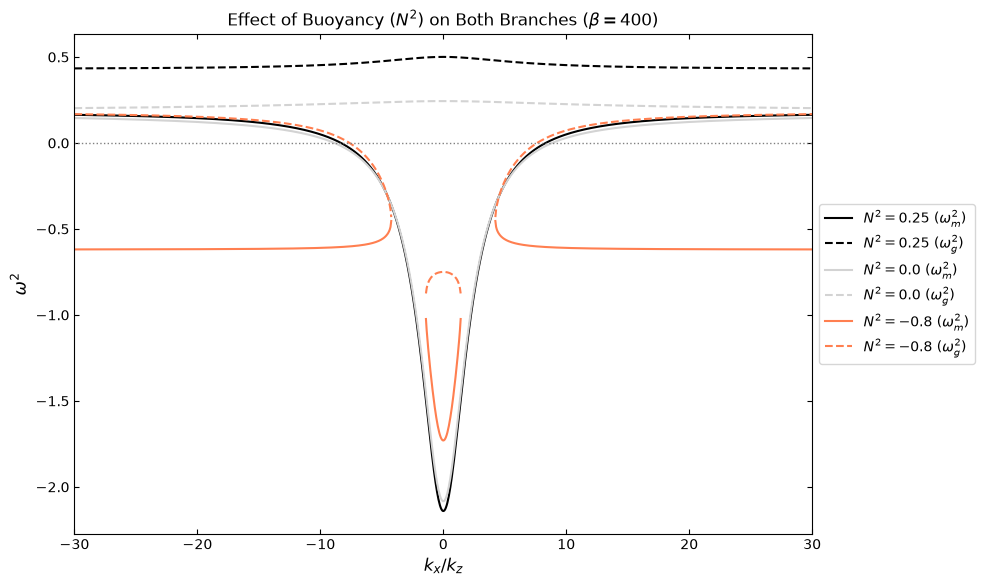

In [4]:
fig, ax = plt.subplots(figsize=(10, 6))

#N2_values = [ -3.75]
# N2_values = [0.3,  -.5, -0.8]
N2_values = [0.25, 0.0, -0.8]


#colors = ['black']
#colors = ['lightgray', 'coral', 'red']
colors = ['black', 'lightgray', 'coral']

beta_value = 400

kx_kz = np.linspace(-30, 30, 1000)

for N2, color in zip(N2_values, colors):
    w2_m, w2_g = calculate_w2(
        N2, beta=beta_value, kx_kz=kx_kz
    )

    ax.plot(kx_kz, w2_m, color=color, linewidth=1.5, linestyle='-',
            label=fr'$N^2 = {N2}$ ($\omega_m^2$)')

    ax.plot(kx_kz, w2_g, color=color, linewidth=1.5, linestyle='--',
            label=fr'$N^2 = {N2}$ ($\omega_g^2$)')

ax.axhline(0, color='gray', linestyle=':', linewidth=1)
ax.set_xlim(-30, 30)


ax.set_xlabel(r'$k_x/k_z$', fontsize=12)
ax.set_ylabel(r'$\omega^2$', fontsize=12)
ax.set_title(rf'Effect of Buoyancy ($N^2$) on Both Branches ($\beta = {beta_value}$)')

ax.legend(loc='center left', bbox_to_anchor=(1, 0.5))
plt.tight_layout()

ax.tick_params(axis='both', direction='in', top=True, right=True)

plt.show()

$\quad$ É natural, portanto, construir um mapa de estabilidade diante dos diferentes impactos que as variáveis $\beta$ e $N^2$ exercem sobre o sistema. Dessa forma, foram construídas `grids` para essas duas variáveis, a partir das quais calculamos os ramos magnético e de inércia-gravidade da relação de dispersão. Permitindo visualizar como o quadrado dos autovalores, $\omega^2$, varia com a intensidade do campo magnético e com a estratificação térmica. A escala de cores representa os valores de $\omega^2$, utilizando a mesma escala nos dois mapas para facilitar a comparação entre os modos. A linha preta indica a fronteira em que $\omega^2 = 0$, enquanto a linha pontilhada vertical marca $N^2 = 0$, distinguindo os regimes de estratificação convectivamente estável ($N^2 > 0$) e instável ($N^2 < 0$). Quando $\omega^2$ é real e positivo, a frequência $\omega$ também é real, e as perturbações apresentam comportamento oscilatório, caracterizando modos estáveis. Por outro lado, quando $\omega^2$ é real e negativo, a frequência $\omega$ é puramente imaginária, de modo que as soluções podem crescer ou decair exponencialmente no tempo, caracterizando uma instabilidade linear. 

$\quad$ Entretanto, quando o discriminante da relação de dispersão é negativo, os valores de $\omega^2$ tornam-se complexos, resultando em frequências com partes real e imaginária não nulas. Nesse caso, as perturbações apresentam comportamento oscilatório combinado com crescimento ou decaimento exponencial, sendo necessário analisar as partes real e imaginária da frequência para caracterizar sua estabilidade. Essas regiões não são representadas nos mapas, pois a função utilizada retorna valores indefinidos para raízes de discriminantes negativos. Além disso, o eixo da variável $\beta$ está em escala logarítmica, uma vez que essa grandeza pode variar por várias ordens de magnitude; valores elevados de $\beta$ correspondem a campos magnéticos relativamente mais fracos, enquanto valores menores indicam campos mais intensos.

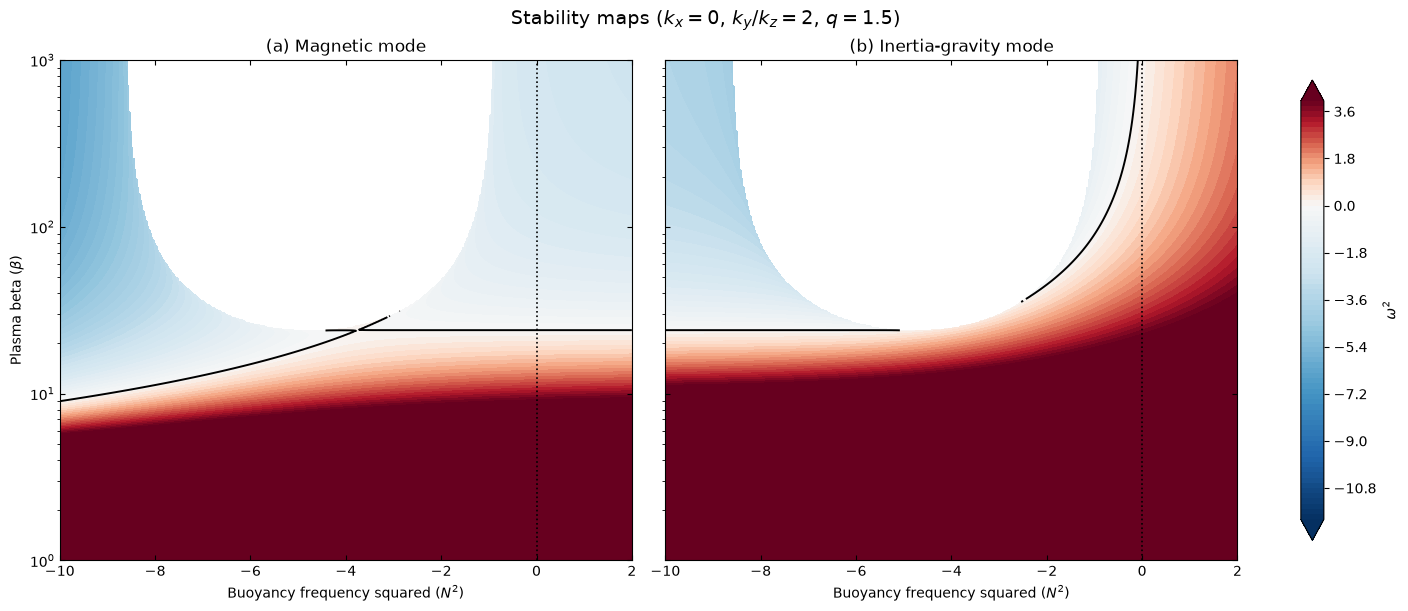

In [5]:
# Grade de parâmetros
N2_vals = np.linspace(-10, 2, 400)
beta_vals = np.logspace(0, 3, 400)
N2_grid, beta_grid = np.meshgrid(N2_vals, beta_vals)

# Calcula os dois modos com kx = 0
w2_m, w2_g = calculate_w2(
    N2_grid, beta_grid,
    q=1.5, kz=6.0, ky_ratio=2.0, kx_kz=0.0
)

# Painel
fig, axes = plt.subplots(
    1, 2, figsize=(14, 6),
    sharex=True, sharey=True,
    constrained_layout=True
)

levels = np.linspace(-12, 4, 81)
norm = TwoSlopeNorm(vmin=-12, vcenter=0, vmax=4)

plots = [
    (axes[0], w2_m, '(a) Magnetic mode'),
    (axes[1], w2_g, '(b) Inertia-gravity mode')
]

for ax, data, panel_title in plots:
    contour = ax.contourf(
        N2_grid, beta_grid, data,
        levels=levels, cmap='RdBu_r',
        norm=norm, extend='both'
    )

    # Fronteira de estabilidade
    ax.contour(
        N2_grid, beta_grid, data,
        levels=[0], colors='black',
        linewidths=1.4
    )

    # Estratificação neutra
    ax.axvline(0, color='black', linestyle=':', linewidth=1.2)

    ax.set_title(panel_title)
    ax.set_xlabel(r'Buoyancy frequency squared ($N^2$)')
    ax.set_yscale('log')
    ax.set_xlim(-10, 2)
    ax.set_ylim(1, 1000)
    ax.tick_params(axis='both', direction='in', top=True, right=True)

axes[0].set_ylabel(r'Plasma beta ($\beta$)')

cbar = fig.colorbar(contour, ax=axes, location='right', shrink=0.92)
cbar.set_label(r'$\omega^2$')

fig.suptitle(
    r'Stability maps ($k_x=0$, $k_y/k_z=2$, $q=1.5$)',
    fontsize=14
)

plt.show()


$\quad$ É possível observar um ponto de sela próximo de $N^2 \approx -4$, cuja natureza e implicações não foram exploradas neste projeto. Entretanto, visualmente, essa região parece delimitar a transição entre comportamentos associados a valores positivos e negativos de $\omega^2$. Também é possível observar a coexistência da instabilidade convectiva, associada a $N^2 < 0$, com a instabilidade do ramo magnético. Dessa forma, o mapa sintetiza o comportamento dos dois modos diante das variações na estratificação térmica e na intensidade do campo magnético, evidenciando as diferentes regiões de estabilidade e instabilidade do sistema.

## 5. Conclusões

$\quad$ Neste estudo linear, os modos magnético e de inércia-gravidade permanecem bem separados sob campos magnéticos intensos (baixo $\beta$), indicando um acoplamento limitado entre eles. Por outro lado, sob campos mais fracos (alto $\beta$), os ramos passam a interagir mais fortemente e apresentam regiões de sobreposição e aproximação, especialmente em regimes convectivamente instáveis ($N^2 < 0$).

$\quad$ Esse comportamento sugere uma possível hibridização entre a instabilidade magnetorrotacional (MRI) e a instabilidade convectiva, na qual mecanismos inicialmente associados a modos distintos podem contribuir conjuntamente para uma instabilidade acoplada. Assim, os resultados evidenciam que a intensidade do campo magnético e a estratificação térmica desempenham papéis importantes na dinâmica linear das perturbações.

$\quad$ Entretanto, a análise apresentada não permite determinar, por si só, como esse acoplamento influencia o desenvolvimento não linear do sistema ou a turbulência impulsionada pela MRI. Investigações adicionais são necessárias para compreender as implicações desses resultados para a evolução dinâmica dos discos de acreção.

## 6. Referências

[1] Mamatsashvili, G.R., Chagelishvili, G.D., Bodo, G. and Rossi, P. (2013) ‘Revisiting linear dynamics of non-axisymmetric perturbations in weakly magnetized accretion discs’, Monthly Notices of the Royal Astronomical Society, 435(3), pp. 2552–2567. doi:10.1093/mnras/stt1470.

[2] Balbus, S. A., &amp; Hawley, J. F. (1991). A powerful local shear instability in weakly magnetized disks. *The Astrophysical Journal*, 376, 214-222.

[3] Mishra, A. (2025) Simulations of magnetorotational instability in liquid-metal Taylor–Couette experiments. PhD thesis. Technische Universität Berlin. doi:10.14279/depositonce-23580.

[4] Mishra, A., Mamatsashvili, G., Seilmayer, M. and Stefani, F. (2024) ‘One-winged butterflies: mode selection for azimuthal magnetorotational instability by thermal convection’, Journal of Fluid Mechanics, 992, R1. doi:10.1017/jfm.2024.517.

[5] Clarke, D.A. (2025) A First Course in Magnetohydrodynamics. Cambridge: Cambridge University Press. doi:10.1017/9781009381468.